# 3.6 Generalización

> Borrador de la sección 3.6 (Jose). Se integra en `model_development.ipynb`.

**Qué pide el enunciado:** mostrar que el modelo funciona con datos que no vio, sin sobreajuste ni fuga.

**Cómo:** test 2024 (los hiperparámetros ya estaban elegidos con los folds), deriva 2025, entidades que no estaban en el train, ablación de las features con riesgo de fuga y SHAP global enlazado a las hipótesis H1-H7. Los intervalos son IC 95 % con bootstrap **por entidad** (200 repeticiones): los contratos de una misma entidad están correlacionados y remuestrear contratos daría intervalos demasiado estrechos.

> Nota honesta: durante el desarrollo de J1 y J2 se miró 2024 como control de cordura (reproducir las cifras de la F0 y probar el `Pipeline`). Ninguna elección de hiperparámetros, features o modelo se hizo con esas cifras.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # el borrador vive en notebooks/; el notebook final, en la raiz de final-project/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RECALCULAR = False     # True vuelve a correr la evaluacion completa (unos 9 min) y reescribe resultados/j3_*
if RECALCULAR:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.evaluar_j3"], cwd=RAIZ, check=True)
j3 = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))
modelos = pd.read_csv(RES / "j3_test2024_modelos.csv")

def tabla(t, metricas, nombres=None):
    t = t[t["metrica"].isin(metricas)].copy()
    t["valor [IC]"] = [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(t["valor"], t["ic_inf"], t["ic_sup"])]
    t["dif. vs regla [IC]"] = [f"{a:+.3f} [{b:+.3f}, {c:+.3f}]" for a, b, c in zip(t["dif"], t["dif_ic_inf"], t["dif_ic_sup"])]
    out = t.pivot(index="modelo", columns="metrica", values=["valor [IC]", "dif. vs regla [IC]"])
    return out.reindex(nombres) if nombres else out

## Test 2024

In [2]:
orden = ["regla_base", "regla_entidad", "hgb", "rf", "arbol", "svm", "knn"]
display(tabla(modelos, ["pr_auc", "roc_auc"], orden))
print("Criterio de aceptación (IC de la diferencia de PR-AUC contra la regla excluye 0):", j3["criterio_aceptacion_final"])

valor [IC]                        \
metrica                      pr_auc               roc_auc   
modelo                                                      
regla_base     0.247 [0.215, 0.285]  0.500 [0.500, 0.500]   
regla_entidad  0.470 [0.355, 0.562]  0.682 [0.628, 0.726]   
hgb            0.584 [0.488, 0.659]  0.781 [0.752, 0.807]   
rf             0.580 [0.481, 0.657]  0.779 [0.748, 0.806]   
arbol          0.537 [0.441, 0.616]  0.751 [0.721, 0.782]   
svm            0.523 [0.404, 0.613]  0.730 [0.689, 0.766]   
knn            0.509 [0.392, 0.604]  0.719 [0.678, 0.754]   

                    dif. vs regla [IC]                           
metrica                         pr_auc                  roc_auc  
modelo                                                           
regla_base     -0.223 [-0.292, -0.129]  -0.182 [-0.226, -0.128]  
regla_entidad  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
hgb            +0.114 [+0.082, +0.158]  +0.099 [+0.067, +0.130]  
rf             +0.110 [+0.081, +0.148]  +0.097 [+0.067, +0.125]  
arbol          +0.067 [+0.036, +0.113]  +0.070 [+0.039, +0.100]  
svm            +0.053 [+0.030, +0.085]  +0.048 [+0.033, +0.070]  
knn            +0.039 [+0.015, +0.065]  +0.037 [+0.014, +0.060]

Criterio de aceptación (IC de la diferencia de PR-AUC contra la regla excluye 0): True


**Interpretación:** el HGB llega a 0,584 de PR-AUC frente a 0,470 de la regla por entidad (+0,114, IC [+0,082; +0,158]) y 0,247 de la tasa base, así que cumple el criterio de aceptación del plan. Las cifras de 2024 son parecidas a las de los folds (0,577), señal de que la búsqueda no sobreajustó la validación. Los cinco modelos le ganan a la regla, pero solo los ensambles lo hacen por un margen amplio.

## Deriva 2025

- (i) El **mismo modelo** entrenado con 2019-2023, evaluado en 2025.
- (ii) El modelo **reentrenado** con 2019-2024, evaluado en 2025.

In [3]:
der = pd.read_csv(RES / "j3_deriva_2025.csv")
print(f"2025: {j3['deriva_2025']['n']:,} contratos maduros, tasa base {j3['deriva_2025']['tasa_base']:.3f}")
display(tabla(der, ["pr_auc", "roc_auc"], ["regla_base", "regla_entidad", "final_2019_2023", "regla_entidad_2019_2024", "final_2019_2024"]))

2025: 99,702 contratos maduros, tasa base 0.271


valor [IC]                        \
metrica                                pr_auc               roc_auc   
modelo                                                                
regla_base               0.271 [0.243, 0.305]  0.500 [0.500, 0.500]   
regla_entidad            0.465 [0.385, 0.540]  0.656 [0.624, 0.691]   
final_2019_2023          0.550 [0.472, 0.642]  0.773 [0.747, 0.797]   
regla_entidad_2019_2024  0.467 [0.380, 0.543]  0.664 [0.629, 0.698]   
final_2019_2024          0.550 [0.469, 0.664]  0.785 [0.759, 0.811]   

                              dif. vs regla [IC]                           
metrica                                   pr_auc                  roc_auc  
modelo                                                                     
regla_base               -0.194 [-0.253, -0.131]  -0.156 [-0.191, -0.124]  
regla_entidad            +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
final_2019_2023          +0.084 [+0.033, +0.157]  +0.116 [+0.090, +0.143]  
regla_entidad_2019_2024  +0.002 [-0.006, +0.008]  +0.008 [-0.000, +0.015]  
final_2019_2024          +0.085 [+0.029, +0.173]  +0.129 [+0.103, +0.156]

**Interpretación:** en 2025 el modelo congelado baja de 0,584 a 0,550 de PR-AUC, pero le sigue ganando a la regla (+0,084, IC [+0,033; +0,157]) y el ROC-AUC casi no cambia (0,781 → 0,773). Reentrenar con 2024 no mejora el PR-AUC (0,550 en los dos casos), aunque sube un poco el ROC-AUC. Por eso el artefacto v1 se queda con 2019-2023 y el reentrenamiento se decide con la regla campeón-retador de la sección 3.9.

Recordatorio: `y_dias` salta a 20 % en 2025 por cómo se registra `dias_adicionados`, no por un cambio de comportamiento; con la etiqueta aprobada `y` la tasa de 2025 (0,271) está dentro del rango de los otros años.

## Entidades no vistas en el train

La regla por entidad no sabe nada de una entidad nueva (le da a todos sus contratos la tasa base). El modelo sí puede usar el resto de variables.

In [4]:
nv = j3["no_vistas"]
print(f"Contratos de 2024 de entidades no vistas: {nv['n']:,} ({nv['positivos']} positivos)")
for m in ("pr_auc", "roc_auc"):
    f = nv["final"][m]
    print(f"  {m}: {f['valor']:.3f} [{f['ic_inf']:.3f}, {f['ic_sup']:.3f}] | dif. vs regla {f['dif']:+.3f} [{f['dif_ic_inf']:+.3f}, {f['dif_ic_sup']:+.3f}]")
g = pd.read_csv(RES / "j3_por_grupo_2024.csv")
display(g[g["tipo"] == "entidad"][["modelo", "grupo", "n", "tasa_base", "pr_auc", "roc_auc"]])

Contratos de 2024 de entidades no vistas: 1,834 (211 positivos)
  pr_auc: 0.279 [0.170, 0.449] | dif. vs regla +0.164 [+0.069, +0.307]
  roc_auc: 0.721 [0.655, 0.791] | dif. vs regla +0.221 [+0.155, +0.291]


,modelo,grupo,n,tasa_base,pr_auc,roc_auc
0,final,no vista,1834,0.115,0.279,0.721
1,final,vista,86254,0.250,0.587,0.781
7,regla_entidad,no vista,1834,0.115,0.115,0.500
8,regla_entidad,vista,86254,0.250,0.474,0.685


**Interpretación:** en las entidades nuevas el modelo tiene ROC-AUC 0,721 y le gana a la regla por +0,221 (IC [+0,155; +0,291]). Es la parte más clara del aporte del modelo: sirve justo donde no hay historia. Son solo 211 positivos, por eso el intervalo del PR-AUC es ancho.

## Ablación: ¿la ventaja depende de las features con riesgo de fuga?

- `FEATURES_ABLACION_J3` = `dias_firma_a_inicio` y `fin_planeado_cruza_anio` (usan la fecha de inicio, "segura con limitación" en `docs/LISTA_FUGA.md`). Es la ablación obligatoria.
- `FEATURES_POR_VERIFICAR` = las 8 que se asumen fijas tras la firma pero no están comprobadas.

In [5]:
print("Ablación obligatoria:", F.FEATURES_ABLACION_J3)
print(f"Por verificar ({len(F.FEATURES_POR_VERIFICAR)}):", F.FEATURES_POR_VERIFICAR)
abl = pd.read_csv(RES / "j3_ablacion_2024.csv")
display(tabla(abl, ["pr_auc", "roc_auc_intra_pares"], ["regla_entidad", "final", "sin_ablacion_j3", "sin_por_verificar"]))

Ablación obligatoria: ['dias_firma_a_inicio', 'fin_planeado_cruza_anio']
Por verificar (8): ['log_pago_adelantado', 'p_proveedores_invitados', 'p_proveedores_con_invitacion', 'p_proveedores_que_manifestaron', 'p_respuestas_al_procedimiento', 'p_respuestas_externas', 'p_conteo_de_respuestas_a_ofertas', 'p_proveedores_unicos_con']


valor [IC]                        \
metrica                          pr_auc   roc_auc_intra_pares   
modelo                                                          
regla_entidad      0.470 [0.355, 0.562]  0.500 [0.500, 0.500]   
final              0.584 [0.488, 0.659]  0.701 [0.597, 0.757]   
sin_ablacion_j3    0.580 [0.488, 0.655]  0.698 [0.597, 0.754]   
sin_por_verificar  0.584 [0.489, 0.661]  0.701 [0.597, 0.757]   

                        dif. vs regla [IC]                           
metrica                             pr_auc      roc_auc_intra_pares  
modelo                                                               
regla_entidad      +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  
final              +0.114 [+0.082, +0.158]  +0.201 [+0.097, +0.257]  
sin_ablacion_j3    +0.110 [+0.079, +0.153]  +0.198 [+0.097, +0.254]  
sin_por_verificar  +0.114 [+0.083, +0.157]  +0.201 [+0.097, +0.257]

**Interpretación:** sin las dos features de la fecha de inicio la ventaja sobre la regla casi no cambia (PR-AUC de +0,114 a +0,110; ROC-AUC dentro de entidad de +0,201 a +0,198) y los intervalos siguen lejos de 0. Quitar las 8 por verificar tampoco cambia nada. **La conclusión no depende de las variables con riesgo de fuga.**

**Decisión:** se mantienen las features.
- **Alternativas:** quitar las dos de la ablación o las 8 por verificar por precaución.
- **Por qué:** no aportan mucho, pero tampoco cambian la conclusión; la limitación de la fecha de inicio (no ve cambios anteriores a la primera modificación) se cita como limitación.
- **Evidencia:** tabla de arriba.
- `el_contrato_puede_ser_prorrogado` sigue excluida y no se evaluó en la ablación [NO EVALUADO].

## SHAP global y las hipótesis H1-H7

`TreeExplainer` sobre el HGB con 3.000 contratos de 2024. Las columnas transformadas se suman por feature original.

Error de aditividad máximo: 7.4e-13 (la suma de SHAP reproduce la salida del modelo)


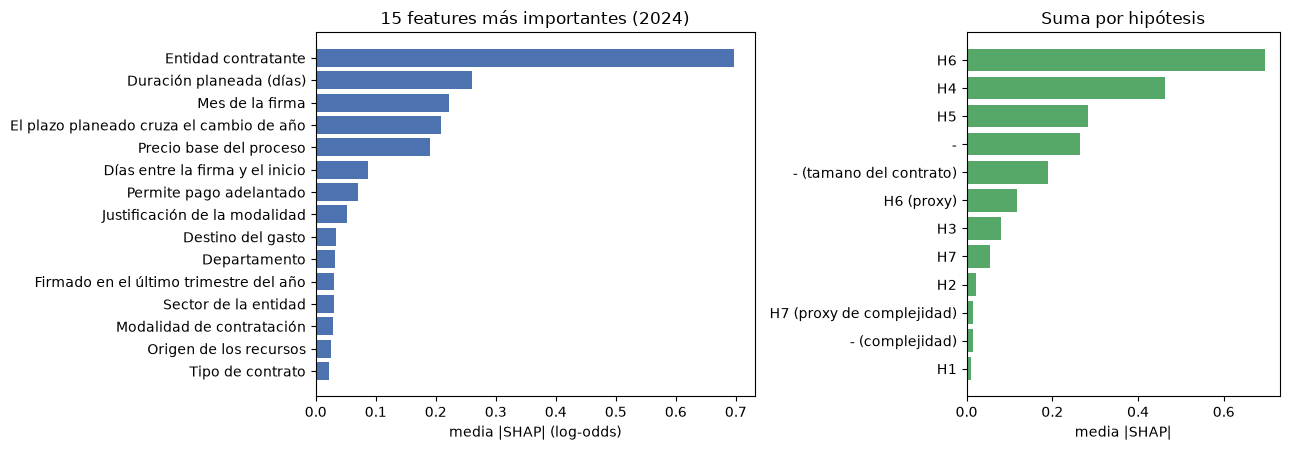

In [6]:
sh = pd.read_csv(RES / "j3_shap_global_2024.csv", index_col=0)
print(f"Error de aditividad máximo: {j3['shap']['error_aditividad_max']:.1e} (la suma de SHAP reproduce la salida del modelo)")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
top = sh.head(15)[::-1]
ax[0].barh([F.NOMBRES_LEGIBLES[f] for f in top.index], top["media_abs_shap"], color="#4C72B0")
ax[0].set_xlabel("media |SHAP| (log-odds)"); ax[0].set_title("15 features más importantes (2024)")
h = sh.groupby("hipotesis")["media_abs_shap"].sum().sort_values()
ax[1].barh(h.index, h.values, color="#55A868"); ax[1].set_title("Suma por hipótesis"); ax[1].set_xlabel("media |SHAP|")
plt.tight_layout(); plt.show()

**Interpretación:**
- **H6 (historia de la entidad)** es la señal dominante: `nit_entidad`, vía el `TargetEncoder`, suma más que cualquier otro grupo. Es coherente con que la regla por entidad sola ya llegue a 0,470 de PR-AUC.
- **H4 (calendario)**: el mes de la firma y si el fin planeado cruza el año son la segunda familia. Coincide con el EDA: enero 34 % de positivos frente a noviembre 16 %.
- **H5 (duración planeada)** y el **tamaño del contrato** (precio base) vienen después.
- **H2 (competencia)** y **H1 (tiempo entre publicación y firma)** aportan muy poco; la ablación de las 8 por verificar (casi todas de H2) lo confirma.
- Una advertencia: SHAP muestra en qué se apoya el modelo, no causalidad.